In [12]:
import numpy as np
import h5py
from pathlib import Path

def create_h5_dataset(data_dir, sites_path, out_h5="qubit_dataset.h5"):
    data_dir = Path(data_dir)

    image_files = sorted(data_dir.glob("*i.npy"))
    images = []
    labels = []

    for img_path in image_files:
        prefix = img_path.name[:-5]  # removes "i.npy"
        label_path = data_dir / f"{prefix}t.npy"
        assert label_path.exists(), f"Missing label: {label_path}"
        images.append(np.load(img_path))
        labels.append(np.load(label_path))

    images = np.asarray(images, dtype=np.float32)
    labels = np.asarray(labels)
    sites = np.asarray(np.load(sites_path), dtype=np.float32)

    assert images.shape[0] == labels.shape[0], "Number of images and labels must match"
    assert labels.shape[1] == sites.shape[0], "Number of labels per image must match number of sites"

    with h5py.File(out_h5, "w") as f:
        f.create_dataset("images", data=images)
        f.create_dataset("labels", data=labels)
        f.create_dataset("sites", data=sites)

    print("Saved:", out_h5)
    print("images:", images.shape)
    print("labels:", labels.shape)
    print("sites:", sites.shape)


create_h5_dataset(data_dir="data/0.1", sites_path="data/sites.npy", out_h5="qubit_dataset.h5")

Saved: qubit_dataset.h5
images: (100, 768, 768)
labels: (100, 1024)
sites: (1024, 2)


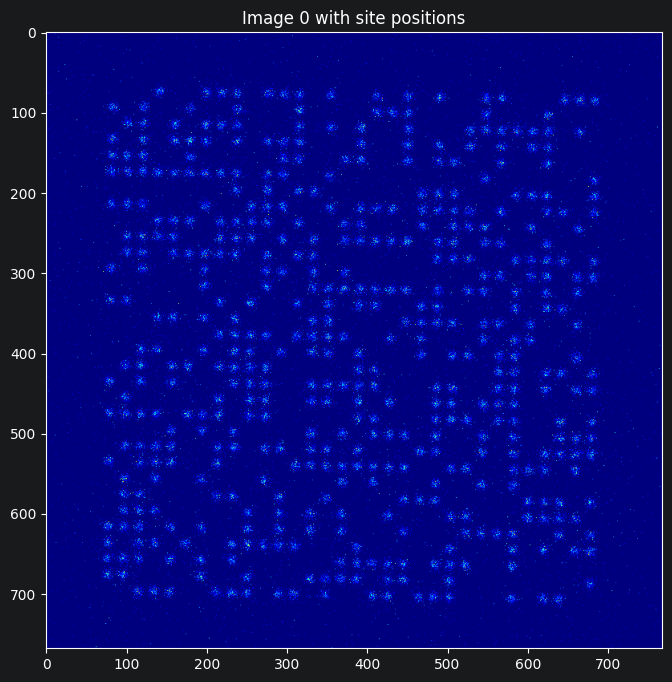

In [27]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

with h5py.File("qubit_dataset_sim.h5", "r") as f:
    image = f["images"][1]      # first image
    sites = f["sites"][:]       # shape: (num_sites, 2)

plt.figure(figsize=(8, 8))
plt.imshow(image, cmap="jet")
# plt.scatter(sites[:, 0], sites[:, 1], s=5, c="red", marker="o")
plt.title("Image 0 with site positions")
plt.show()

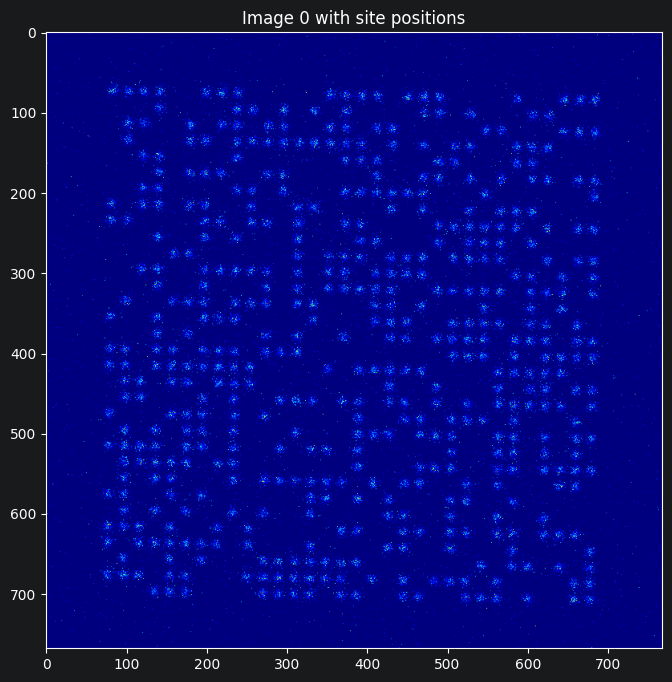

In [28]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

with h5py.File("qubit_dataset_sim.h5", "r") as f:
    image = f["images"][2]      # first image
    sites = f["sites"][:]       # shape: (num_sites, 2)

plt.figure(figsize=(8, 8))
plt.imshow(image, cmap="jet")
# plt.scatter(sites[:, 0], sites[:, 1], s=5, c="red", marker="o")
plt.title("Image 0 with site positions")
plt.show()

In [22]:
import numpy as np
from scipy.spatial import cKDTree

sites = np.load("data/sites.npy")   # shape: (1024, 2), x,y

tree = cKDTree(sites)

# k=2 because the closest point is the site itself at distance 0
distances, neighbor_indices = tree.query(sites, k=2)

nearest_distances = distances[:, 1]

print("nearest-neighbor distances:")
print("mean:", nearest_distances.mean())
print("median:", np.median(nearest_distances))
print("std:", nearest_distances.std())
print("min:", nearest_distances.min())
print("max:", nearest_distances.max())

nearest-neighbor distances:
mean: 19.399999999999952
median: 19.399999999999956
std: 5.611922065320862e-14
min: 19.399999999999782
max: 19.400000000000126


In [23]:
import h5py
import numpy as np
import torch


def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")   # MacBook GPU
    return torch.device("cpu")


def load_h5(h5_path):
    with h5py.File(h5_path, "r") as f:
        images = f["images"][:].astype(np.float32)
        labels = f["labels"][:].astype(np.float32)
        sites = f["sites"][:].astype(np.float32)

    assert images.ndim == 3, "images should be (N, H, W)"
    assert labels.ndim == 2, "labels should be (N, num_sites)"
    assert sites.ndim == 2 and sites.shape[1] == 2, "sites should be (num_sites, 2)"
    assert labels.shape[1] == sites.shape[0], "labels and sites do not match"

    return images, labels, sites


def split_data(N, train_frac=0.6, val_frac=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(N)

    n_train = int(train_frac * N)
    n_val = int(val_frac * N)

    train_idx = idx[:n_train]
    val_idx = idx[n_train:n_train + n_val]
    test_idx = idx[n_train + n_val:]

    return train_idx, val_idx, test_idx


def preprocess_images(images, train_idx):
    """
    Simple paper-like preprocessing:
    subtract training-set mean intensity and normalize by training-set range.
    """
    mean_value = images[train_idx].mean()
    images = images - mean_value

    scale = np.max(np.abs(images[train_idx]))
    if scale == 0:
        scale = 1.0

    images = images / scale
    return images.astype(np.float32), float(mean_value), float(scale)


def extract_site_patches(images, sites, s=12):
    """
    Returns X with shape:
        (N, num_sites, s*s)

    sites are assumed to be x,y coordinates.
    images are indexed as image[y, x].
    """
    N, H, W = images.shape
    num_sites = sites.shape[0]

    half = s // 2
    X = np.zeros((N, num_sites, s * s), dtype=np.float32)

    for q, (x, y) in enumerate(sites):
        x = int(round(x))
        y = int(round(y))

        y0 = y - half
        y1 = y0 + s
        x0 = x - half
        x1 = x0 + s

        if y0 < 0 or x0 < 0 or y1 > H or x1 > W:
            raise ValueError(f"Site {q} patch goes outside image: x={x}, y={y}, s={s}")

        patch = images[:, y0:y1, x0:x1]
        X[:, q, :] = patch.reshape(N, s * s)

    return X


def add_bias(X):
    """
    X: (N, num_sites, num_features)
    returns: (N, num_sites, num_features + 1)
    """
    N, Q, _ = X.shape
    ones = torch.ones((N, Q, 1), device=X.device, dtype=X.dtype)
    return torch.cat([X, ones], dim=-1)


def train_matched_filter(X_train, y_train, alpha=1e-4, device=None):
    """
    X_train: (N_train, num_sites, num_features)
    y_train: (N_train, num_sites)

    Returns:
        W: (num_sites, num_features + 1)
    """
    if device is None:
        device = get_device()

    X = torch.tensor(X_train, dtype=torch.float32, device=device)
    y = torch.tensor(y_train, dtype=torch.float32, device=device)

    X = add_bias(X)

    # A[q] = X_q.T @ X_q
    A = torch.einsum("nqf,nqg->qfg", X, X)

    # b[q] = X_q.T @ y_q
    b = torch.einsum("nqf,nq->qf", X, y)

    Q, F, _ = A.shape
    I = torch.eye(F, device=device).unsqueeze(0).repeat(Q, 1, 1)

    # Do not regularize the bias term
    I[:, -1, -1] = 0.0

    A = A + alpha * I

    W = torch.linalg.solve(A, b.unsqueeze(-1)).squeeze(-1)

    return W


def predict_scores(X, W, device=None):
    """
    X: (N, num_sites, num_features)
    W: (num_sites, num_features + 1)

    Returns:
        scores: (N, num_sites)
    """
    if device is None:
        device = W.device

    X = torch.tensor(X, dtype=torch.float32, device=device)
    X = add_bias(X)

    scores = torch.einsum("nqf,qf->nq", X, W)
    return scores


def choose_thresholds(scores_val, y_val):
    """
    Choose one threshold per site using validation accuracy.

    scores_val: torch tensor, (N_val, num_sites)
    y_val: numpy array or torch tensor, (N_val, num_sites)

    Returns:
        thresholds: torch tensor, (num_sites,)
    """
    device = scores_val.device

    if not torch.is_tensor(y_val):
        y_val = torch.tensor(y_val, dtype=torch.float32, device=device)
    else:
        y_val = y_val.to(device).float()

    thresholds = torch.linspace(0.01, 0.99, 99, device=device)

    # preds: (num_thresholds, N_val, num_sites)
    preds = scores_val.unsqueeze(0) >= thresholds[:, None, None]
    correct = preds == (y_val.unsqueeze(0) > 0.5)

    acc = correct.float().mean(dim=1)   # (num_thresholds, num_sites)
    best = torch.argmax(acc, dim=0)

    return thresholds[best]


def evaluate(scores, y, thresholds):
    device = scores.device

    if not torch.is_tensor(y):
        y = torch.tensor(y, dtype=torch.float32, device=device)
    else:
        y = y.to(device).float()

    preds = scores >= thresholds[None, :]
    target = y > 0.5

    accuracy = (preds == target).float().mean().item()

    false_bright = ((preds == 1) & (target == 0)).sum().float()
    total_dark = (target == 0).sum().float().clamp_min(1)

    false_dark = ((preds == 0) & (target == 1)).sum().float()
    total_bright = (target == 1).sum().float().clamp_min(1)

    p_false_bright = false_bright / total_dark
    p_false_dark = false_dark / total_bright

    fidelity = 1.0 - 0.5 * (p_false_bright + p_false_dark)

    return {
        "accuracy": accuracy,
        "fidelity": fidelity.item(),
        "false_bright": p_false_bright.item(),
        "false_dark": p_false_dark.item(),
    }


def main():
    h5_path = "qubit_dataset.h5"
    s = 12
    alpha = 1e-4

    device = get_device()
    print("Using device:", device)

    images, labels, sites = load_h5(h5_path)

    print("images:", images.shape)
    print("labels:", labels.shape)
    print("sites:", sites.shape)

    N = images.shape[0]
    train_idx, val_idx, test_idx = split_data(N)

    images, mean_value, scale = preprocess_images(images, train_idx)

    print("preprocessing mean:", mean_value)
    print("preprocessing scale:", scale)

    X = extract_site_patches(images, sites, s=s)

    X_train = X[train_idx]
    y_train = labels[train_idx]

    X_val = X[val_idx]
    y_val = labels[val_idx]

    X_test = X[test_idx]
    y_test = labels[test_idx]

    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

    W = train_matched_filter(
        X_train=X_train,
        y_train=y_train,
        alpha=alpha,
        device=device,
    )

    scores_val = predict_scores(X_val, W, device=device)
    thresholds = choose_thresholds(scores_val, y_val)

    scores_test = predict_scores(X_test, W, device=device)
    metrics = evaluate(scores_test, y_test, thresholds)

    print("\nTest results")
    print("accuracy:", metrics["accuracy"])
    print("fidelity:", metrics["fidelity"])
    print("false bright:", metrics["false_bright"])
    print("false dark:", metrics["false_dark"])

    # Save trained model
    torch.save(
        {
            "W": W.detach().cpu(),
            "thresholds": thresholds.detach().cpu(),
            "s": s,
            "alpha": alpha,
            "mean_value": mean_value,
            "scale": scale,
            "sites": torch.tensor(sites),
        },
        "mf_site_model.pt",
    )

    print("\nSaved model: mf_site_model.pt")


if __name__ == "__main__":
    main()

Using device: mps
images: (100, 768, 768)
labels: (100, 1024)
sites: (1024, 2)
preprocessing mean: 201.98768615722656
preprocessing scale: 123.01231384277344
X_train: (60, 1024, 144)
y_train: (60, 1024)

Test results
accuracy: 0.9571777582168579
fidelity: 0.9575096964836121
false bright: 0.08498062193393707
false dark: 0.0

Saved model: mf_site_model.pt
